In [10]:
#Import modules
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re



In [11]:
df = pd.read_csv('data/Titanic.csv', sep=',')

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0.0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1.0,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1.0,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1.0,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0.0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [15]:
df.isna().sum()


PassengerId       0
Survived        418
Pclass            0
Name              0
Sex               0
Age               0
SibSp             0
Parch             0
Ticket            0
Fare              1
Cabin          1014
Embarked          2
dtype: int64

In [16]:
# mean age
print('Mean of "Age" is %.2f' %(df["Age"].mean(skipna=True)))
# median age
print('Median of "Age" is %.2f' %(df["Age"].median(skipna=True)))


Mean of "Age" is 29.50
Median of "Age" is 28.00


In [14]:
df["Age"] = df["Age"].fillna(df["Age"].median())
# To fill with a set value or a char, change .fillna("desired value")


In [8]:
df["Age"] = df["Age"].fillna(df["Age"].median())
# To fill with a set value or a char, change .fillna("desired value")


In [17]:
df["HasCabin"] = df.Cabin.notnull()

In [21]:
df.head(5)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,HasCabin,Title
0,1,0.0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,False,Mr
1,2,1.0,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,True,Mrs
2,3,1.0,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,False,Miss
3,4,1.0,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,True,Mrs
4,5,0.0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,False,Mr


In [20]:
df["Title"] = df.Name.apply(lambda x: re.search(' ([A-Z][a-z]+)\.', x).group(1)) 


<>:1: SyntaxWarning: invalid escape sequence '\.'
<>:1: SyntaxWarning: invalid escape sequence '\.'
/var/folders/gk/p4lwbnk179sckbsdq4vn1mhm0000gn/T/ipykernel_87747/2792879580.py:1: SyntaxWarning: invalid escape sequence '\.'
  df["Title"] = df.Name.apply(lambda x: re.search(' ([A-Z][a-z]+)\.', x).group(1))


In [23]:
df["Title"].value_counts() # you need to replace "column" 
# with the name of the column you want to count


Title
Mr        757
Miss      264
Mrs       198
Master     61
Unique     29
Name: count, dtype: int64

In [28]:
df["Title"].value_counts() # you need to replace "column" 
# with the name of the column you want to count


Title
Mr        757
Miss      264
Mrs       198
Master     61
Unique     29
Name: count, dtype: int64

In [24]:
df["Title"] = df["Title"].replace({'Mlle':'Miss', 'Mme':'Mrs', 'Ms':'Miss'})


In [26]:
df["Title"] = df["Title"].replace(["Rev","Dr", "Col", "Major", "Don", "Lady", "Sir", "Capt", "Countess", "Jonkheer", "Dona"], "Unique")


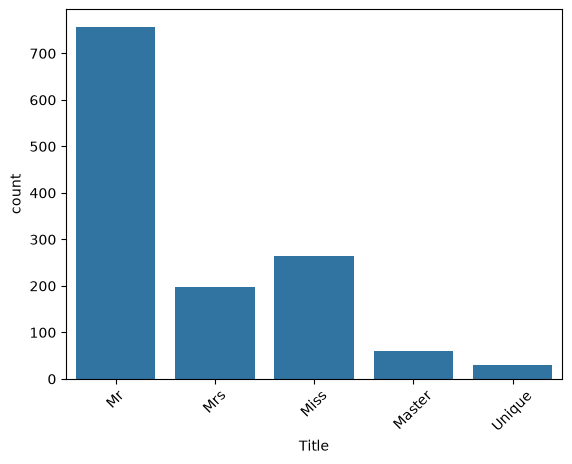

In [30]:
sns.countplot(data=df, x='Title')  # Seaborn countplot
plt.xticks(rotation=45);



In [31]:
df['CatAge'] = pd.qcut(df["Age"], q=4, labels=False )
df['CatFare'] = pd.qcut(df["Fare"], q=4, labels=False )


In [32]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,HasCabin,Title,CatAge,CatFare
0,1,0.0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,False,Mr,0,0.0
1,2,1.0,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,True,Mrs,3,3.0
2,3,1.0,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,False,Miss,1,1.0
3,4,1.0,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,True,Mrs,2,3.0
4,5,0.0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,False,Mr,2,1.0


In [33]:
df = df.drop(["Name", "Ticket", "Fare","Cabin"], axis=1)


In [34]:
df.head()

,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Embarked,HasCabin,Title,CatAge,CatFare
0,1,0.0,3,male,22.0,1,0,S,False,Mr,0,0.0
1,2,1.0,1,female,38.0,1,0,C,True,Mrs,3,3.0
2,3,1.0,3,female,26.0,0,0,S,False,Miss,1,1.0
3,4,1.0,1,female,35.0,1,0,S,True,Mrs,2,3.0
4,5,0.0,3,male,35.0,0,0,S,False,Mr,2,1.0


In [35]:
df = pd.get_dummies(df, columns=["Sex", "Embarked", "Title"], drop_first=True)

In [36]:
df.head()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,HasCabin,CatAge,CatFare,Sex_male,Embarked_Q,Embarked_S,Title_Miss,Title_Mr,Title_Mrs,Title_Unique
0,1,0.0,3,22.0,1,0,False,0,0.0,True,False,True,False,True,False,False
1,2,1.0,1,38.0,1,0,True,3,3.0,False,False,False,False,False,True,False
2,3,1.0,3,26.0,0,0,False,1,1.0,False,False,True,True,False,False,False
3,4,1.0,1,35.0,1,0,True,2,3.0,False,False,True,False,False,True,False
4,5,0.0,3,35.0,0,0,False,2,1.0,True,False,True,False,True,False,False


In [37]:
df.to_csv('data/Titanic_Cleaned.csv', index=False)
